# Workshop 3: Fashion-MNIST with a feed-forward network

Fashion-MNIST contains 60,000 training and 10,000 test images, each 28 by 28 pixels,
in ten clothing categories. Repeat the MNIST workflow, inspect the model summary,
and vary depth, activation, epoch count and learning rate.

**Evaluation plan:** compare settings on one fixed validation split, choose the
configuration and epoch using validation loss, then retrain on the full training
set and evaluate the selected model on the test set once. This avoids using test
scores to tune the model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import fashion_mnist
from keras import models, layers
from keras.utils import to_categorical
from IPython.display import Markdown, display

keras.utils.set_random_seed(42)

## 1. Load and inspect Fashion-MNIST

Training: (60000, 28, 28) (60000,)
Test:     (10000, 28, 28) (10000,)


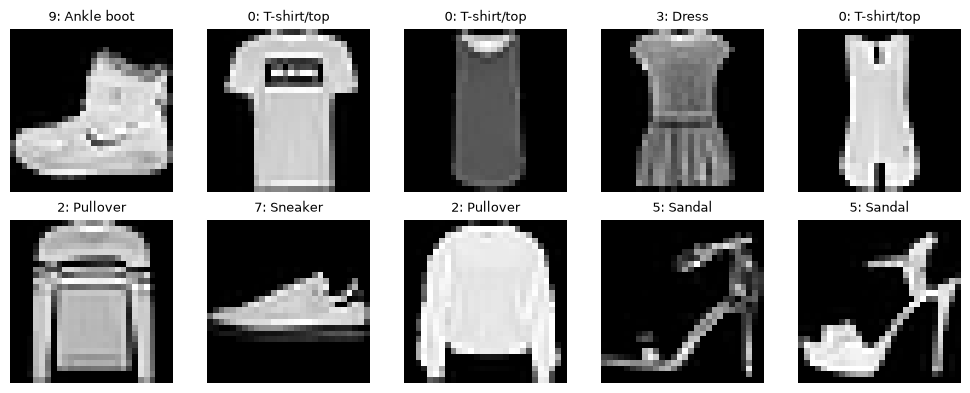

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
print('Training:', x_train.shape, y_train.shape)
print('Test:    ', x_test.shape, y_test.shape)

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f'{y_train[i]}: {class_names[y_train[i]]}', fontsize=9)
    ax.axis('off')
fig.tight_layout()
plt.show()

## 2. Prepare the data and hold out validation examples

Flatten 28 by 28 to 784 values, scale pixels to 0-1, and one-hot encode the ten
categories. Keep the original arrays unchanged. A seeded permutation holds out
10,000 training examples for validation; the other 50,000 update the weights.
All experiments use these same examples. No test scores are used in this comparison.

In [3]:
train_images = x_train.reshape(len(x_train), -1).astype('float32') / 255.0
train_labels = to_categorical(y_train, num_classes=10).astype('float32')
indices = np.random.default_rng(42).permutation(len(train_images))
val_indices, fit_indices = indices[:10000], indices[10000:]
x_fit, y_fit = train_images[fit_indices], train_labels[fit_indices]
x_val, y_val = train_images[val_indices], train_labels[val_indices]
print('Training subset:', x_fit.shape, y_fit.shape)
print('Validation:     ', x_val.shape, y_val.shape)
print('Pixel range:', train_images.min(), 'to', train_images.max())

Training subset: (50000, 784) (50000, 10)
Validation:      (10000, 784) (10000, 10)
Pixel range: 0.0 to 1.0


## 3. Define the network and inspect its summary

The baseline is **784 inputs -> Dense(512, ReLU) -> Dense(10, softmax)**.
There are 407,050 trainable parameters, including the bias for every dense unit.
`learning_rate` is the current argument name for RMSprop; the handout's `lr`
argument is from an older Keras API.

In [4]:
def build_network(hidden_layers=(512,), activation='relu', learning_rate=0.001):
    model = models.Sequential([layers.Input(shape=(784,))])
    for units in hidden_layers:
        model.add(layers.Dense(units, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=learning_rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

network = build_network()
network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Run controlled experiments

Each run creates a fresh model with seed 42 and batch size 128. Matching seeds
makes runs easier to compare; different architectures still have different weights,
and one seed does not measure run-to-run variability. Change one setting at a time.

| Run | Change from baseline |
|---|---|
| A | Baseline: one 512-unit hidden layer, ReLU, 5 epochs, learning rate 0.001 |
| B | Two hidden layers: 512 then 256 units |
| C | tanh hidden activation |
| D | 15 epochs |
| E1 | Learning rate 0.005 |
| E2 | Learning rate 0.0001 |

In [5]:
def run_experiment(name, hidden_layers=(512,), activation='relu', epochs=5, learning_rate=0.001):
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    model = build_network(hidden_layers, activation, learning_rate)
    print(name)
    history = model.fit(x_fit, y_fit, epochs=epochs, batch_size=128,
                        validation_data=(x_val, y_val), verbose=2).history
    best_epoch = int(np.argmin(history['val_loss'])) + 1
    return {
        'name': name, 'hidden_layers': hidden_layers, 'activation': activation,
        'epochs': epochs, 'learning_rate': learning_rate,
        'parameters': model.count_params(), 'history': history,
        'best_epoch': best_epoch, 'best_val_loss': history['val_loss'][best_epoch - 1],
    }

results = {}
results['A'] = run_experiment('A: baseline')

A: baseline
Epoch 1/5
391/391 - 1s - 2ms/step - accuracy: 0.7923 - loss: 0.5856 - val_accuracy: 0.8419 - val_loss: 0.4212
Epoch 2/5
391/391 - 1s - 2ms/step - accuracy: 0.8529 - loss: 0.4014 - val_accuracy: 0.8622 - val_loss: 0.3622
Epoch 3/5
391/391 - 1s - 2ms/step - accuracy: 0.8710 - loss: 0.3508 - val_accuracy: 0.8725 - val_loss: 0.3357
Epoch 4/5
391/391 - 1s - 1ms/step - accuracy: 0.8830 - loss: 0.3199 - val_accuracy: 0.8798 - val_loss: 0.3268
Epoch 5/5
391/391 - 1s - 2ms/step - accuracy: 0.8911 - loss: 0.2973 - val_accuracy: 0.8802 - val_loss: 0.3210


In [6]:
results['B'] = run_experiment('B: two hidden layers', hidden_layers=(512, 256))

B: two hidden layers
Epoch 1/5
391/391 - 1s - 3ms/step - accuracy: 0.7915 - loss: 0.5738 - val_accuracy: 0.8546 - val_loss: 0.3875
Epoch 2/5
391/391 - 1s - 2ms/step - accuracy: 0.8549 - loss: 0.3898 - val_accuracy: 0.8689 - val_loss: 0.3485
Epoch 3/5
391/391 - 1s - 2ms/step - accuracy: 0.8725 - loss: 0.3418 - val_accuracy: 0.8756 - val_loss: 0.3356
Epoch 4/5
391/391 - 1s - 2ms/step - accuracy: 0.8851 - loss: 0.3098 - val_accuracy: 0.8784 - val_loss: 0.3387
Epoch 5/5
391/391 - 1s - 2ms/step - accuracy: 0.8933 - loss: 0.2863 - val_accuracy: 0.8829 - val_loss: 0.3243


In [7]:
results['C'] = run_experiment('C: tanh activation', activation='tanh')

C: tanh activation
Epoch 1/5
391/391 - 1s - 3ms/step - accuracy: 0.7830 - loss: 0.6174 - val_accuracy: 0.8325 - val_loss: 0.4424
Epoch 2/5
391/391 - 1s - 2ms/step - accuracy: 0.8399 - loss: 0.4369 - val_accuracy: 0.8503 - val_loss: 0.3962
Epoch 3/5
391/391 - 1s - 1ms/step - accuracy: 0.8562 - loss: 0.3912 - val_accuracy: 0.8567 - val_loss: 0.3739
Epoch 4/5
391/391 - 1s - 2ms/step - accuracy: 0.8672 - loss: 0.3616 - val_accuracy: 0.8645 - val_loss: 0.3596
Epoch 5/5
391/391 - 1s - 2ms/step - accuracy: 0.8750 - loss: 0.3394 - val_accuracy: 0.8692 - val_loss: 0.3491


In [8]:
results['D'] = run_experiment('D: 15 epochs', epochs=15)

D: 15 epochs
Epoch 1/15
391/391 - 1s - 2ms/step - accuracy: 0.7923 - loss: 0.5856 - val_accuracy: 0.8419 - val_loss: 0.4212
Epoch 2/15
391/391 - 1s - 1ms/step - accuracy: 0.8529 - loss: 0.4014 - val_accuracy: 0.8622 - val_loss: 0.3622
Epoch 3/15
391/391 - 1s - 2ms/step - accuracy: 0.8710 - loss: 0.3508 - val_accuracy: 0.8725 - val_loss: 0.3357
Epoch 4/15
391/391 - 1s - 1ms/step - accuracy: 0.8830 - loss: 0.3199 - val_accuracy: 0.8798 - val_loss: 0.3268
Epoch 5/15
391/391 - 1s - 2ms/step - accuracy: 0.8911 - loss: 0.2973 - val_accuracy: 0.8802 - val_loss: 0.3210
Epoch 6/15
391/391 - 1s - 2ms/step - accuracy: 0.8978 - loss: 0.2797 - val_accuracy: 0.8821 - val_loss: 0.3200
Epoch 7/15
391/391 - 1s - 2ms/step - accuracy: 0.9024 - loss: 0.2649 - val_accuracy: 0.8841 - val_loss: 0.3188
Epoch 8/15
391/391 - 1s - 1ms/step - accuracy: 0.9070 - loss: 0.2520 - val_accuracy: 0.8884 - val_loss: 0.3153
Epoch 9/15
391/391 - 1s - 1ms/step - accuracy: 0.9123 - loss: 0.2396 - val_accuracy: 0.8876 - val_l

In [9]:
results['E1'] = run_experiment('E1: learning rate 0.005', learning_rate=0.005)
results['E2'] = run_experiment('E2: learning rate 0.0001', learning_rate=0.0001)

E1: learning rate 0.005
Epoch 1/5
391/391 - 1s - 2ms/step - accuracy: 0.7710 - loss: 0.7365 - val_accuracy: 0.8438 - val_loss: 0.4172
Epoch 2/5
391/391 - 1s - 1ms/step - accuracy: 0.8447 - loss: 0.4205 - val_accuracy: 0.8499 - val_loss: 0.3982
Epoch 3/5
391/391 - 1s - 1ms/step - accuracy: 0.8638 - loss: 0.3732 - val_accuracy: 0.8648 - val_loss: 0.3617
Epoch 4/5
391/391 - 1s - 1ms/step - accuracy: 0.8743 - loss: 0.3459 - val_accuracy: 0.8702 - val_loss: 0.3757
Epoch 5/5
391/391 - 1s - 2ms/step - accuracy: 0.8812 - loss: 0.3260 - val_accuracy: 0.8753 - val_loss: 0.3717
E2: learning rate 0.0001
Epoch 1/5
391/391 - 1s - 2ms/step - accuracy: 0.7612 - loss: 0.7680 - val_accuracy: 0.8163 - val_loss: 0.5358
Epoch 2/5
391/391 - 1s - 1ms/step - accuracy: 0.8323 - loss: 0.5014 - val_accuracy: 0.8373 - val_loss: 0.4649
Epoch 3/5
391/391 - 1s - 1ms/step - accuracy: 0.8471 - loss: 0.4516 - val_accuracy: 0.8476 - val_loss: 0.4320
Epoch 4/5
391/391 - 1s - 2ms/step - accuracy: 0.8555 - loss: 0.4235 - v

## 5. Compare validation results

The first three scores below describe the **last epoch** of each experiment.
The last two columns identify the best validation-loss epoch within that run.
Loss is used consistently to select both the configuration and epoch budget.

The baseline and 15-epoch runs use the same initial weights and training order.
Their curves overlap for the first five epochs in the plot below.


In [10]:
header = '| Experiment | Hidden units | Activation | Epochs | LR | Parameters | Final train acc | Final val acc | Final val loss | Best epoch | Best val loss |'
rows = [header, '|' + '---|' * 11]
for r in results.values():
    h = r['history']
    rows.append(f"| {r['name']} | {r['hidden_layers']} | {r['activation']} | {r['epochs']} | "
                f"{r['learning_rate']} | {r['parameters']:,} | {h['accuracy'][-1]:.4f} | "
                f"{h['val_accuracy'][-1]:.4f} | {h['val_loss'][-1]:.4f} | "
                f"{r['best_epoch']} | {r['best_val_loss']:.4f} |")
display(Markdown('\n'.join(rows)))

| Experiment | Hidden units | Activation | Epochs | LR | Parameters | Final train acc | Final val acc | Final val loss | Best epoch | Best val loss |
|---|---|---|---|---|---|---|---|---|---|---|
| A: baseline | (512,) | relu | 5 | 0.001 | 407,050 | 0.8911 | 0.8802 | 0.3210 | 5 | 0.3210 |
| B: two hidden layers | (512, 256) | relu | 5 | 0.001 | 535,818 | 0.8933 | 0.8829 | 0.3243 | 5 | 0.3243 |
| C: tanh activation | (512,) | tanh | 5 | 0.001 | 407,050 | 0.8750 | 0.8692 | 0.3491 | 5 | 0.3491 |
| D: 15 epochs | (512,) | relu | 15 | 0.001 | 407,050 | 0.9338 | 0.8899 | 0.3414 | 8 | 0.3153 |
| E1: learning rate 0.005 | (512,) | relu | 5 | 0.005 | 407,050 | 0.8812 | 0.8753 | 0.3717 | 3 | 0.3617 |
| E2: learning rate 0.0001 | (512,) | relu | 5 | 0.0001 | 407,050 | 0.8616 | 0.8579 | 0.3956 | 5 | 0.3956 |

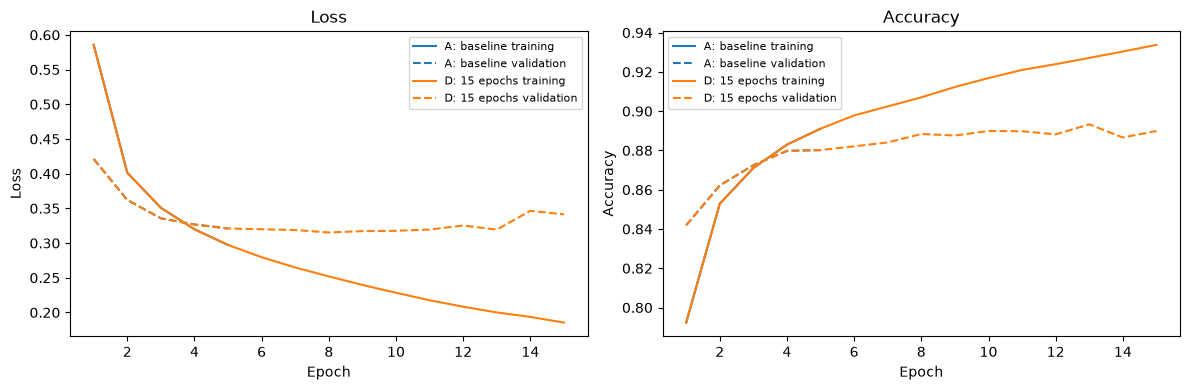

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key in ['A', 'D']:
    r = results[key]
    h = r['history']
    epochs = range(1, len(h['loss']) + 1)
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        line, = ax.plot(epochs, h[metric], label=f"{r['name']} training")
        ax.plot(epochs, h['val_' + metric], '--', color=line.get_color(),
                label=f"{r['name']} validation")
for ax, metric in zip(axes, ['Loss', 'Accuracy']):
    ax.set(xlabel='Epoch', ylabel=metric, title=metric)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Select, retrain and test once

Select the run with the lowest validation loss and its best epoch. Rebuild a fresh
model and train on all 60,000 original training examples for that many epochs.
Only now prepare and evaluate the 10,000 test images. The test result is a final
check of this selection, not a reason to try further settings on the same test set.

In [12]:
best = min(results.values(), key=lambda r: r['best_val_loss'])
print(f"Selected {best['name']}, epoch {best['best_epoch']}, validation loss {best['best_val_loss']:.4f}")
keras.backend.clear_session()
keras.utils.set_random_seed(42)
final_model = build_network(best['hidden_layers'], best['activation'], best['learning_rate'])
final_model.fit(train_images, train_labels, epochs=best['best_epoch'], batch_size=128, verbose=2)
test_images = x_test.reshape(len(x_test), -1).astype('float32') / 255.0
test_labels = to_categorical(y_test, num_classes=10).astype('float32')
test_loss, test_acc = final_model.evaluate(test_images, test_labels, verbose=0)
print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_acc:.2%}')

Selected D: 15 epochs, epoch 8, validation loss 0.3153
Epoch 1/8
469/469 - 1s - 2ms/step - accuracy: 0.8002 - loss: 0.5585
Epoch 2/8
469/469 - 1s - 1ms/step - accuracy: 0.8597 - loss: 0.3856
Epoch 3/8
469/469 - 1s - 1ms/step - accuracy: 0.8763 - loss: 0.3388
Epoch 4/8
469/469 - 1s - 1ms/step - accuracy: 0.8856 - loss: 0.3109
Epoch 5/8
469/469 - 1s - 2ms/step - accuracy: 0.8928 - loss: 0.2898
Epoch 6/8
469/469 - 1s - 2ms/step - accuracy: 0.8990 - loss: 0.2723
Epoch 7/8
469/469 - 1s - 2ms/step - accuracy: 0.9041 - loss: 0.2589
Epoch 8/8
469/469 - 1s - 2ms/step - accuracy: 0.9089 - loss: 0.2465
Final test loss: 0.3697
Final test accuracy: 87.44%


## 7. Reflection on the measured results

In [13]:
a, b, c, d = (results[k] for k in ['A', 'B', 'C', 'D'])
display(Markdown(f"""
- **Baseline:** final validation accuracy {a['history']['val_accuracy'][-1]:.2%}, loss {a['history']['val_loss'][-1]:.4f}.
- **Depth:** the two-layer model has {b['parameters'] - a['parameters']:,} extra parameters and final validation accuracy {b['history']['val_accuracy'][-1]:.2%}. Extra capacity has a computation and memory cost; the score records the benefit in this run.
- **Activation:** tanh gives final validation accuracy {c['history']['val_accuracy'][-1]:.2%}, compared with {a['history']['val_accuracy'][-1]:.2%} for ReLU. No timing comparison was measured.
- **Epochs:** the 15-epoch run finishes at training accuracy {d['history']['accuracy'][-1]:.2%} and validation accuracy {d['history']['val_accuracy'][-1]:.2%}. Its lowest validation loss occurs at epoch {d['best_epoch']}. If validation loss rises while training loss falls, that is evidence of overfitting.
- **Learning rate:** final validation losses are {results['E1']['history']['val_loss'][-1]:.4f} at 0.005, {a['history']['val_loss'][-1]:.4f} at 0.001, and {results['E2']['history']['val_loss'][-1]:.4f} at 0.0001. Compare these within the same five-epoch budget; a slower rate may benefit from more epochs.
- **Selection:** {best['name']} at epoch {best['best_epoch']} had the lowest observed validation loss. Retraining that setting gives **{test_acc:.2%} test accuracy**.
- **Limits:** these are single-seed comparisons on one validation split. They do not establish a fixed model ceiling or a reliable distribution of run-to-run variation. Repeated seeds would be needed for stronger claims about small differences.
"""))


- **Baseline:** final validation accuracy 88.02%, loss 0.3210.
- **Depth:** the two-layer model has 128,768 extra parameters and final validation accuracy 88.29%. Extra capacity has a computation and memory cost; the score records the benefit in this run.
- **Activation:** tanh gives final validation accuracy 86.92%, compared with 88.02% for ReLU. No timing comparison was measured.
- **Epochs:** the 15-epoch run finishes at training accuracy 93.38% and validation accuracy 88.99%. Its lowest validation loss occurs at epoch 8. If validation loss rises while training loss falls, that is evidence of overfitting.
- **Learning rate:** final validation losses are 0.3717 at 0.005, 0.3210 at 0.001, and 0.3956 at 0.0001. Compare these within the same five-epoch budget; a slower rate may benefit from more epochs.
- **Selection:** D: 15 epochs at epoch 8 had the lowest observed validation loss. Retraining that setting gives **87.44% test accuracy**.
- **Limits:** these are single-seed comparisons on one validation split. They do not establish a fixed model ceiling or a reliable distribution of run-to-run variation. Repeated seeds would be needed for stronger claims about small differences.
